#  Analyse exploratoire — Ligue des Champions

**Groupe :** Maxime, Loan, Moussa, Mouhamedou et Ousmane — ESEO, Python for Data Science

## Contexte et question

Notre projet cherche à estimer **quels clubs ont le plus de chances de remporter la Ligue des Champions 2026-2027**.

Avant de construire un modèle, cette EDA sert à **connaître nos données** : ce qu'elles contiennent, si on peut leur faire confiance, ce qu'elles racontent sur les matchs passés, et ce qu'elles ne permettent **pas** de conclure.

## Les données

| Table | Source | Une ligne = |
|---|---|---|
| `games.csv` | [Football Data from Transfermarkt](https://www.kaggle.com/datasets/davidcariboo/player-scores) (Kaggle) | **un match**, toutes compétitions confondues (score, date, phase, clubs…) |
| `EloRatings.csv` | [Club Football Match Data 2000-2025](https://www.kaggle.com/datasets/adamgbor/club-football-match-data-2000-2025) (Kaggle) | **le classement Elo d'un club à une date donnée** |

Le **classement Elo** est une note de niveau : chaque club gagne des points quand il gagne un match et en perd quand il perd. Battre une équipe forte rapporte beaucoup de points, battre une équipe faible en rapporte peu. Plus l'Elo est élevé, plus le club est fort à ce moment-là.

## Plan de l'analyse

Le notebook suit les 4 questions d'une EDA :
1. **Qu'ai-je ?** — structure des tables, types de variables ;
2. **Est-ce propre ?** — valeurs manquantes, doublons, incohérences, valeurs aberrantes ;
3. **Que se passe-t-il ?** — buts, résultats, avantage du terrain, meilleurs clubs ;
4. **Qu'est-ce qui manque ?** — biais, limites, ce que l'on ne peut pas affirmer.

# 1. Imports et configuration

Chargement des bibliothèques utilisées dans le notebook :
- `numpy`, `pandas` : calcul et manipulation des tableaux de données ;
- `matplotlib`, `seaborn` : graphiques (histogrammes, heatmap) ;
- `scikit-learn` (régression linéaire, découpage train/test, standardisation, random forest, ACP) : importés en prévision de l'étape de modélisation.

Configuration : 40 lignes affichées au maximum par défaut, graphiques intégrés au notebook en haute résolution (`retina`), taille de figure par défaut de 12 × 6.

**⚠️ Limites :** aucun import `sklearn` n'est encore utilisé dans la suite (ils servent qu'après).

In [20]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

# Configuration
pd.options.display.max_rows = 40
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
mpl.rcParams['figure.figsize'] = (12.0, 6.0)

# 2. Chargement des données

Lecture de deux fichiers CSV situés dans `../data/` :
- `games.csv` : tous les matchs, toutes compétitions confondues (source : Transfermarkt, via Kaggle) ;
- `EloRatings.csv` : classement Elo des clubs dans le temps (source : Club Football Match Data, via Kaggle).

Les autres fichiers (`clubs.csv`, `players.csv`…) ne sont pas utilisés dans l'EDA.

In [21]:
# Charger les données
games = pd.read_csv('../data/games.csv')
elo = pd.read_csv('../data/EloRatings.csv')

print("✅ Données chargées !")

✅ Données chargées !


# 5. Structure de la table `games`

- **Dimensions :** 88 958 lignes × 23 colonnes ; chaque ligne est un match.
- **Colonnes :** identifiants (match, compétition, clubs), saison, tour, date, buts domicile / extérieur, position au classement, entraîneurs, stade, affluence, arbitre, URL, noms des clubs…
- **Contenu :** la table mélange de nombreuses compétitions (championnats nationaux, coupes, compétitions européennes, compétitions de sélections comme `FIWC` ou `EURO`). Le champ `season` correspond à l'année de **début** de saison (la saison 2012 démarre en septembre 2012).

**⚠️ Limite :** seules les 8 premières colonnes sont listées (`[:8]`) ; la sortie de `head(10)` n'est donc qu'un aperçu

In [22]:
# CELLULE 3 : Explorer la structure
print("📊 GAMES.CSV")
print(f"Shape: {games.shape}")
print(f"Colonnes: {list(games.columns)[:8]}...")
print("\nPremières lignes:")
print(games.head(10))

📊 GAMES.CSV
Shape: (88958, 23)
Colonnes: ['game_id', 'competition_id', 'season', 'round', 'date', 'home_club_id', 'away_club_id', 'home_club_goals']...

Premières lignes:
   game_id competition_id  season           round        date  home_club_id  \
0  1026846           FIWC    2009     Round of 16  2010-06-26          3449   
1  1026847           FIWC    2009     Round of 16  2010-06-27          3437   
2  1027001           FIWC    2009     Round of 16  2010-06-26          3505   
3  1027002           FIWC    2009     Round of 16  2010-06-27          3262   
4  1027048           FIWC    2009     Round of 16  2010-06-28          3379   
5  1027049           FIWC    2009     Round of 16  2010-06-29          3581   
6  1027635           FIWC    2009     Round of 16  2010-06-28          3439   
7  1027636           FIWC    2009     Round of 16  2010-06-29          3375   
8  1027723           FIWC    2009  Quarter-Finals  2010-07-02          3449   
9  1027750           FIWC    2009  Quar

# 6. Types de données

- `int64` : identifiants, saison, **buts domicile / extérieur** ;
- `float64` : positions au classement et affluence (ces colonnes contiennent des valeurs manquantes, d'où le type décimal) ;
- `str` (texte) : compétition, tour, **date**, noms, stade, arbitre, URL.

**À retenir :**
- les buts sont en `int64` : ils ne contiennent aucune valeur manquante dans toute la table ;
- la date est stockée comme du texte : une conversion avec `pd.to_datetime` sera nécessaire pour tout calcul temporel.

In [23]:
# CELLULE 4 : Types de données
print("\n🔍 Types de données:")
print(games.dtypes)


🔍 Types de données:
game_id                     int64
competition_id                str
season                      int64
round                         str
date                          str
home_club_id                int64
away_club_id                int64
home_club_goals             int64
away_club_goals             int64
home_club_position        float64
away_club_position        float64
home_club_manager_name        str
away_club_manager_name        str
stadium                       str
attendance                float64
referee                       str
url                           str
home_club_formation           str
away_club_formation           str
home_club_name                str
away_club_name                str
aggregate                     str
competition_type              str
dtype: object


# 6 bis. Structure de la table `elo`

**Question :** à quoi ressemble la table Elo, et couvre-t-elle tous les clubs de Ligue des Champions ?

- **Une ligne = l'Elo d'un club à une date.** Les valeurs sont relevées deux fois par mois (le 1er et le 15).
- **Dimensions :** 273 972 lignes × 4 colonnes (`date`, `club`, `country`, `elo`).
- **Période :** du 1er juillet 2000 au 1er septembre 2026, soit juste avant le début de la saison 2026-2027 que l'on veut prédire.
- **Couverture :** 984 clubs dans **19 pays seulement**.
- **Qualité :** aucune valeur manquante, aucun doublon (même club à la même date).

**⚠️ Limites :**
- Plusieurs pays qui envoient des clubs en Ligue des Champions **ne sont pas couverts** : Ukraine (Shakhtar Donetsk, Dynamo Kyiv), Croatie (Dinamo Zagreb), Serbie (Étoile rouge de Belgrade), Tchéquie (Slavia Prague), Suisse (Young Boys)… Ces clubs n'auront pas d'Elo.
- La colonne `date` est du texte : il faudra la convertir avec `pd.to_datetime` pour fusionner avec les matchs.
- Les noms de clubs ne sont pas écrits comme dans `games` (`Barcelona` / `FC Barcelona`, `Paris SG` / `Paris Saint-Germain`).

In [25]:
# Structure de la table elo
print(f"Dimensions : {elo.shape[0]:,} lignes × {elo.shape[1]} colonnes")
print(f"Période : du {elo['date'].min()} au {elo['date'].max()}")
print(f"Clubs : {elo['club'].nunique()} | Pays : {elo['country'].nunique()}")
print(f"Pays présents : {sorted(elo['country'].unique())}")
print(f"Valeurs manquantes : {elo.isna().sum().sum()}")
print(f"Doublons (même club, même date) : {elo.duplicated(['date', 'club']).sum()}")

elo.sample(5, random_state=42)

Dimensions : 273,972 lignes × 4 colonnes
Période : du 2000-07-01 au 2026-09-01
Clubs : 984 | Pays : 19
Pays présents : ['AUT', 'BEL', 'DEN', 'ENG', 'ESP', 'FIN', 'FRA', 'GER', 'GRE', 'ITA', 'NED', 'NOR', 'POL', 'POR', 'ROM', 'RUS', 'SCO', 'SWE', 'TUR']
Valeurs manquantes : 0
Doublons (même club, même date) : 0


,date,club,country,elo
176316,2018-06-15,Rapid Wien,AUT,1588.18
44450,2005-02-01,Le Havre,FRA,1473.31
249649,2025-09-01,Arles,FRA,1345.14
58709,2006-07-15,Pandurii,ROM,1341.98
34258,2004-01-15,Farul,ROM,1273.47


# 7. Extraction des matchs de Ligue des champions

Filtre `competition_id == 'CL'` → DataFrame `ucl_games` (copie indépendante).

- **1 871 matchs**, saisons **2012 à 2025** (14 saisons).
- **125 matchs par saison** de 2012 à 2023, avec deux exceptions :
  - **2019 : 119 matchs** → saison 2019/20 perturbée par la Covid : quarts, demies et finale disputés en match unique à Lisbonne (96 + 16 + 4 + 2 + 1 = 119) ;
  - **2024 : 189 et 2025 : 188 matchs** → nouveau format « phase de ligue » à 36 clubs (144 + 16 + 16 + 8 + 4 + 1 = 189).

**⚠️ Limites :** le match manquant en 2025 (188 au lieu de 189) est cohérent avec une finale absente des données (dernière date du jeu : 06/05/2026).

In [26]:
# Filtrer les matchs de Ligue des Champions
ucl_games = games[games['competition_id'] == 'CL'].sort_values('date').copy()

print(f"✅ Matchs de Ligue des Champions : {len(ucl_games):,}")
print(f"\n📅 Saisons présentes : {sorted(ucl_games['season'].unique())}")
print("\n📊 Matchs par saison :")
print(ucl_games['season'].value_counts().sort_index())

✅ Matchs de Ligue des Champions : 1,871

📅 Saisons présentes : [np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]

📊 Matchs par saison :
season
2012    125
2013    125
2014    125
2015    125
2016    125
2017    125
2018    125
2019    119
2020    125
2021    125
2022    125
2023    125
2024    189
2025    188
Name: count, dtype: int64


# 7 bis. Checkpoint 1 — Ce que nous savons de nos données

- **Sujet :** les matchs de Ligue des Champions de 2012-2013 à 2025-2026, pour comprendre ce qui fait gagner un club.
- **Une ligne de `ucl_games` = un match de Ligue des Champions** : deux clubs, une date, une phase, un score.
- **Dimensions :** 1 871 matchs × 23 colonnes, 106 clubs différents.
- **Types :** des nombres entiers (buts, saison, identifiants), des décimaux (affluence, positions) et du texte (noms, phase, date, stade).
- **Sources :** Transfermarkt et Club Football Match Data, via Kaggle.
- **Problèmes de qualité déjà repérés :**
  - la date est stockée comme du texte ;
  - les noms de phases ne sont pas uniformes (`last 16 1st leg` / `Last 16 1st Leg`) ;
  - la saison 2025-2026 s'arrête aux demi-finales ;
  - aucun match de 2026-2027 n'est présent.

In [27]:
# À quoi ressemble un match de Ligue des Champions ?
colonnes = ['date', 'season', 'round', 'home_club_name', 'away_club_name',
            'home_club_goals', 'away_club_goals']
ucl_games[colonnes].sample(5, random_state=42)

,date,season,round,home_club_name,away_club_name,home_club_goals,away_club_goals
85871,2025-09-30,2025,Group Stage,Chelsea FC,SL Benfica,1,0
55960,2021-11-24,2021,Group C,Sporting CP,Borussia Dortmund,3,1
88517,2026-05-05,2025,Semi-Finals 2nd Leg,Arsenal FC,Atlético de Madrid,1,0
15398,2014-10-01,2014,Group A,Atlético de Madrid,Juventus FC,1,0
21148,2015-10-21,2015,Group A,Paris Saint-Germain,Real Madrid,0,0


# 8. Nettoyage : suppression des valeurs manquantes

`games.dropna()` supprime toute ligne qui contient au moins une valeur manquante, dans **n'importe quelle colonne** : on passe de 88 958 à 52 344 lignes (−41 %).

**⚠️ Limites importantes :**
- l'opération porte sur **toute la table `games`** (toutes compétitions), pas seulement sur la Ligue des champions ;
- les colonnes `home_club_position` / `away_club_position` sont vides (ou constantes) pour les matchs de C1 (voir la matrice de corrélation, cellule 19) : ces matchs sont donc très probablement **tous supprimés** par `dropna()` — c'est cohérent avec la saison minimale de 2013 (et non 2012) observée à la cellule suivante ;

In [6]:
# CELLULE 6 : Nettoyage - Supprimer les NaN
games_clean = games.dropna()
print(f"Avant: {len(games)} lignes")
print(f"Après: {len(games_clean)} lignes")

Avant: 88958 lignes
Après: 52344 lignes


### 9. Statistiques descriptives (table nettoyée)

Résumé de `home_club_goals`, `away_club_goals` et `season` sur `games_clean` (52 344 matchs) :

Les saisons couvertes vont de 2013 à 2025. La cellule affiche aussi la liste des colonnes et les 3 premières lignes (redondant avec la cellule 5).

**⚠️ Limite :** ces statistiques concernent l'ensemble des compétitions restantes après `dropna`, **pas la Ligue des champions**. Elles ne sont pas comparables directement à celles de la cellule 11.

In [7]:
# CELLULE 7 : Statistiques descriptives
print("\n📈 STATISTIQUES:")
print(games_clean[['home_club_goals', 'away_club_goals', 'season']].describe())

# Voir les noms des colonnes
print("Colonnes disponibles dans games:")
print(games.columns.tolist())

print("\nPremières lignes:")
print(games.head(3))


📈 STATISTIQUES:
       home_club_goals  away_club_goals        season
count     52344.000000     52344.000000  52344.000000
mean          1.536585         1.206939   2019.502751
std           1.302850         1.162120      4.096713
min           0.000000         0.000000   2013.000000
25%           1.000000         0.000000   2016.000000
50%           1.000000         1.000000   2019.000000
75%           2.000000         2.000000   2024.000000
max          10.000000         9.000000   2025.000000
Colonnes disponibles dans games:
['game_id', 'competition_id', 'season', 'round', 'date', 'home_club_id', 'away_club_id', 'home_club_goals', 'away_club_goals', 'home_club_position', 'away_club_position', 'home_club_manager_name', 'away_club_manager_name', 'stadium', 'attendance', 'referee', 'url', 'home_club_formation', 'away_club_formation', 'home_club_name', 'away_club_name', 'aggregate', 'competition_type']

Premières lignes:
   game_id competition_id  season        round        date  home

# 10. Distribution des buts — table nettoyée

Deux histogrammes côte à côte : buts marqués à domicile et à l'extérieur (classes de 0 à 11 buts).

**Lecture :** les distributions sont asymétriques (queue vers la droite) : la grande majorité des équipes marquent 0, 1 ou 2 buts (75 % des équipes marquent 2 buts ou moins), les scores élevés sont rares. Les équipes à domicile marquent un peu plus.

**⚠️ Limites :** graphique construit sur `games_clean` (toutes compétitions, pas seulement la C1), sans titre général ni étiquettes d'axes.

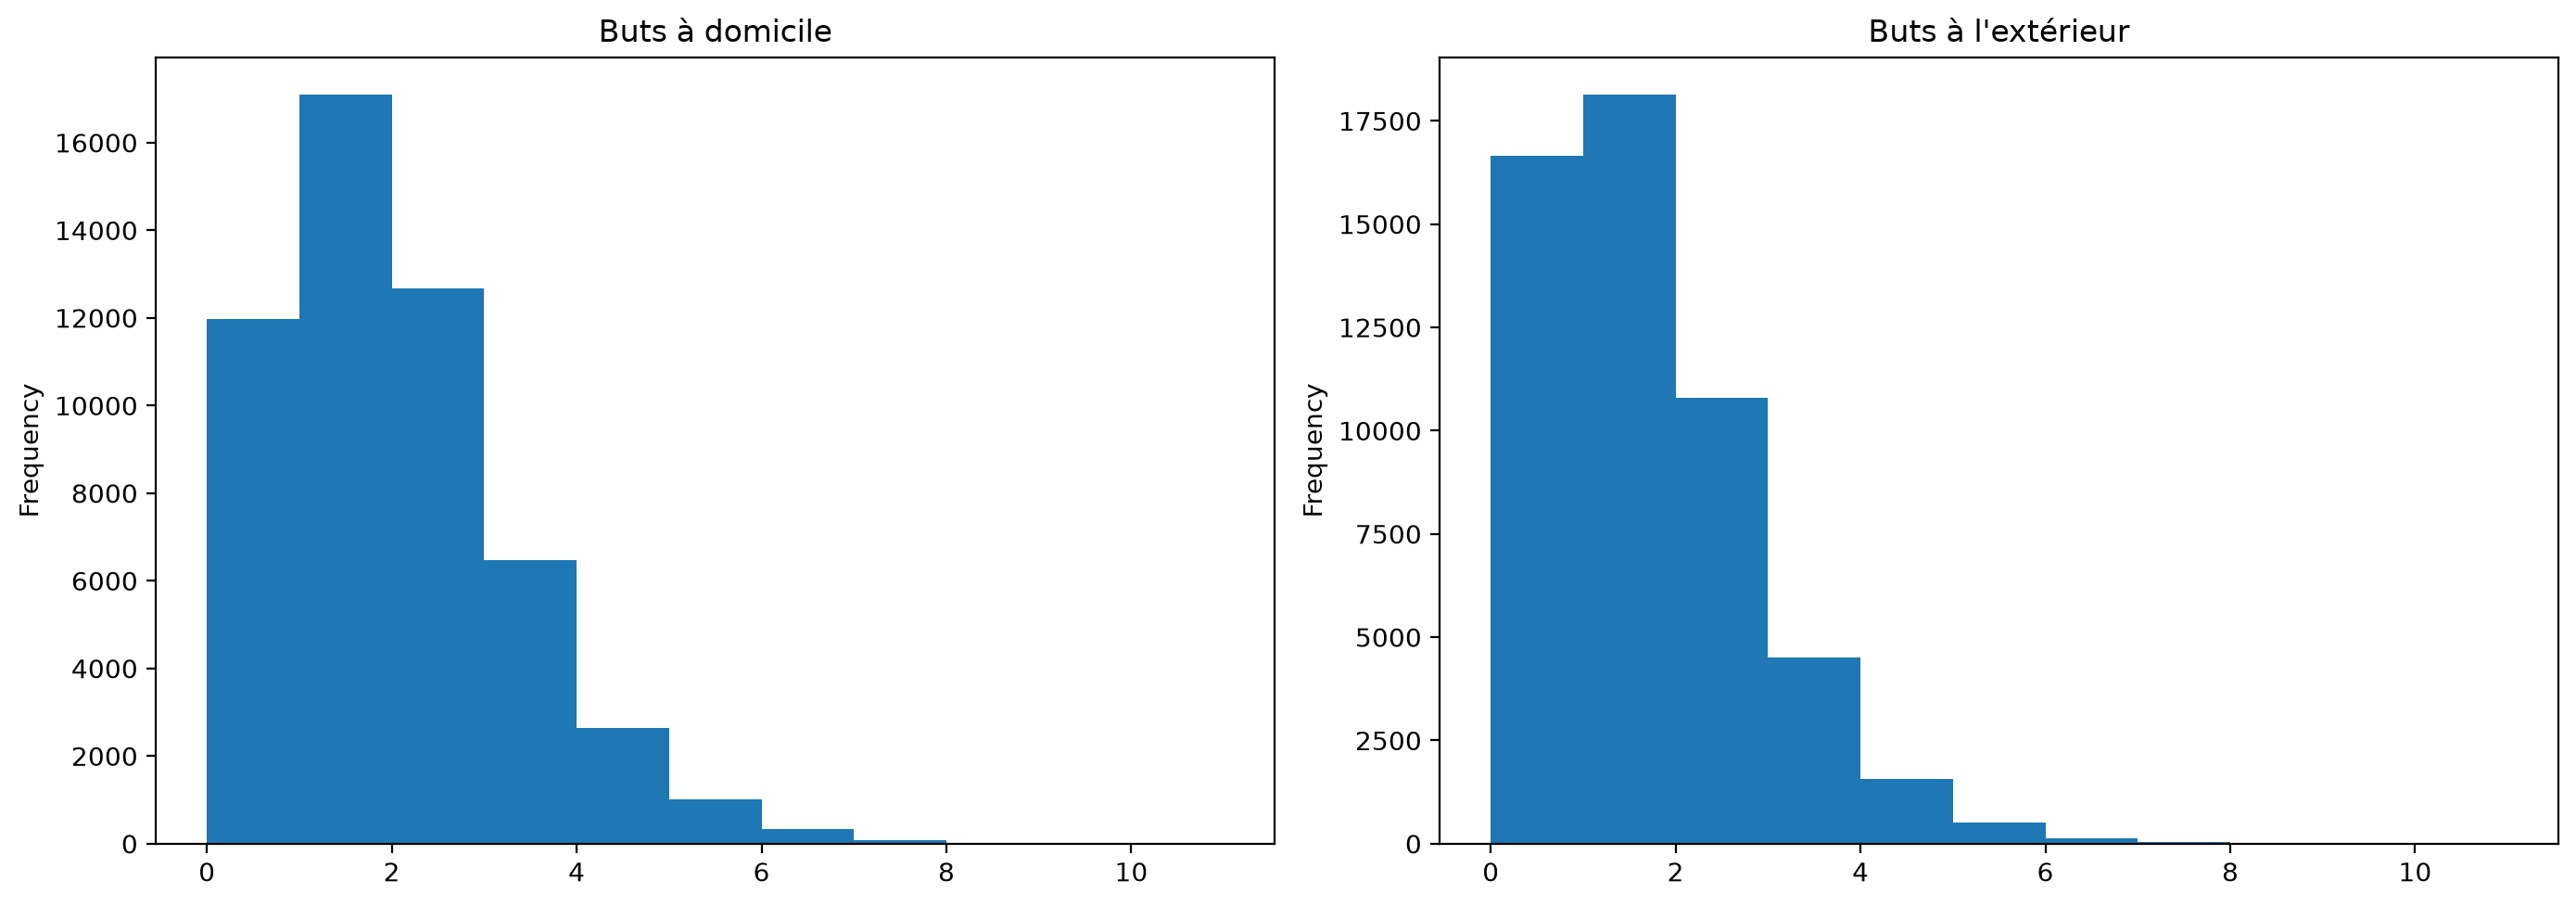

In [8]:
# CELLULE 8 : Distribution des buts
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

bins = np.arange(0, 12)
games_clean['home_club_goals'].plot(kind='hist', bins=bins, ax=ax1, title='Buts à domicile')
games_clean['away_club_goals'].plot(kind='hist', bins=bins, ax=ax2, title='Buts à l\'extérieur')
plt.tight_layout()
plt.show()

### 11. Statistiques descriptives — Ligue des champions

Résumé des buts sur les 1 871 matchs de C1 :

Moyenne d'environ **3,10 buts par match**.

**Lecture :** l'équipe qui reçoit marque en moyenne plus que l'équipe qui se déplace, et la distribution est décalée vers le haut à domicile (3ᵉ quartile de 3 contre 2).

In [9]:
print("\n📊 Descriptive Statistics - Champions League Goals:")
print(ucl_games[['home_club_goals', 'away_club_goals', 'season']].describe())

print("\n⚽ Goal Statistics:")
print(f"  Home team avg goals: {ucl_games['home_club_goals'].mean():.2f}")
print(f"  Away team avg goals: {ucl_games['away_club_goals'].mean():.2f}")
print(f"  Total goals per match: {(ucl_games['home_club_goals'] + ucl_games['away_club_goals']).mean():.2f}")


📊 Descriptive Statistics - Champions League Goals:
       home_club_goals  away_club_goals       season
count      1871.000000      1871.000000  1871.000000
mean          1.738642         1.356494  2018.905398
std           1.488853         1.340688     4.183380
min           0.000000         0.000000  2012.000000
25%           1.000000         0.000000  2015.000000
50%           1.000000         1.000000  2019.000000
75%           3.000000         2.000000  2023.000000
max           9.000000         8.000000  2025.000000

⚽ Goal Statistics:
  Home team avg goals: 1.74
  Away team avg goals: 1.36
  Total goals per match: 3.10


# 13. Top 10 des équipes par nombre de victoires

Méthode : on compte les victoires à domicile et à l'extérieur de chaque club, puis on additionne les deux (`add` avec `fill_value=0` pour les clubs qui n'ont gagné que d'un seul côté).

| Rang | Club | Victoires |
| 1 | Real Madrid | 112 |
| 2 | Bayern Munich | 111 |
| 3 | FC Barcelona | 85 |
| 4 | Paris Saint-Germain | 84 |
| 5 | Manchester City | 77 |
| 6 | Atlético de Madrid | 65 |
| 7 | Juventus FC | 61 |
| 8 | Borussia Dortmund | 60 |
| 9 | Liverpool FC | 56 |
| 10 | Chelsea FC | 49 |

**⚠️ Limites :**
- « historique » signifie ici **2012–2025** seulement ;
- le nombre de victoires dépend du nombre de matchs joués (un club qui va loin en joue plus) : un taux de victoire serait plus équitable ;
- les nuls, les prolongations et les tirs au but ne sont pas pris en compte.

In [10]:
# CELLULE 10 : Top teams
print("\n⭐ TOP 10 TEAMS (historique):")
home_wins = ucl_games[ucl_games['home_club_goals'] > ucl_games['away_club_goals']]['home_club_name'].value_counts()
away_wins = ucl_games[ucl_games['away_club_goals'] > ucl_games['home_club_goals']]['away_club_name'].value_counts()
total_wins = home_wins.add(away_wins, fill_value=0).sort_values(ascending=False)

for i, (team, wins) in enumerate(total_wins.head(10).items(), 1):
    print(f"  {i:2d}. {team:30s} - {int(wins)} victoires")


⭐ TOP 10 TEAMS (historique):
   1. Real Madrid                    - 112 victoires
   2. Bayern Munich                  - 111 victoires
   3. FC Barcelona                   - 85 victoires
   4. Paris Saint-Germain            - 84 victoires
   5. Manchester City                - 77 victoires
   6. Atlético de Madrid             - 65 victoires
   7. Juventus FC                    - 61 victoires
   8. Borussia Dortmund              - 60 victoires
   9. Liverpool FC                   - 56 victoires
  10. Chelsea FC                     - 49 victoires


# 14. Meilleurs clubs selon le classement Elo

On sélectionne les 10 valeurs d'Elo les plus élevées de toute la table, puis on retire les doublons de clubs.

Résultat : seulement **3 clubs** apparaissent — Barcelone (2107,48), Bayern Munich (2101,50) et Real Madrid (2098,62).

**⚠️ Limites :**
- les 10 plus hautes valeurs appartiennent toutes à ces 3 clubs (à différentes dates) ; après suppression des doublons, il n'en reste que 3 : ce n'est **pas un top 10 de clubs** ;
- l'Elo affiché est un pic historique, sans la date correspondante ;

In [11]:
# CELLULE 11 : Corrélation et Elo ratings
print("\n⭐ MEILLEURS CLUBS (par Elo rating):")
top_elo = elo.nlargest(10, 'elo')[['club', 'elo']].drop_duplicates('club')
print(top_elo)


⭐ MEILLEURS CLUBS (par Elo rating):
                 club      elo
115065      Barcelona  2107.48
134066  Bayern Munich  2101.50
135568    Real Madrid  2098.62


# 15. Compétitions présentes dans `games`

Liste des codes de compétition (20 premiers seulement) et nombre de matchs par compétition.

- Les trois grands championnats `GB1`, `ES1`, `IT1` comptent 5 320 matchs chacun, puis `FR1` (4 997), `TR1` (4 618), `L1` (4 284)…
- `CL` (Ligue des champions) : **1 871 matchs** — c'est bien le code utilisé pour le filtre de la cellule 7.
- `CLQ` (1 232 matchs, qualifications de C1), `EL` (2 628) et `ELQ` (2 677) sont des compétitions distinctes.

**⚠️ Limite :** cette vérification arrive après le filtre de la cellule 7 ; logiquement, elle devrait le précéder.

In [12]:
# Vérifier les compétitions disponibles
print("Valeurs de competition_id:")
print(games['competition_id'].unique()[:20])
print(f"\nNombre de matchs par compétition:")
print(games['competition_id'].value_counts())

Valeurs de competition_id:
<ArrowStringArray>
['FIWC', 'EURO', 'NLSC',  'SCI', 'BESC',  'USC',  'DFB',  'ELQ',   'L1',
  'RU1', 'UKR1',  'FR1',  'DK1',  'BE1',  'GB1',  'SC1',  'DFL',  'CLQ',
 'UKRS', 'UKRP']
Length: 20, dtype: str

Nombre de matchs par compétition:
competition_id
GB1     5320
ES1     5320
IT1     5320
FR1     4997
TR1     4618
        ... 
POSU      14
NLSC      13
BESC      13
BPO4      12
UKRS      10
Name: count, Length: 70, dtype: int64


# 16. Distribution des buts — Ligue des champions

Mêmes histogrammes que la cellule 10, mais cette fois sur `ucl_games` : buts à domicile et à l'extérieur en Ligue des champions.

**Lecture :** la médiane est de 1 but des deux côtés, mais la distribution à domicile est décalée vers la droite (3ᵉ quartile : 3 buts contre 2 à l'extérieur). Les scores extrêmes (9 buts à domicile, 8 à l'extérieur) sont très rares.

**⚠️ Limite :** graphiques sans étiquettes d'axes.

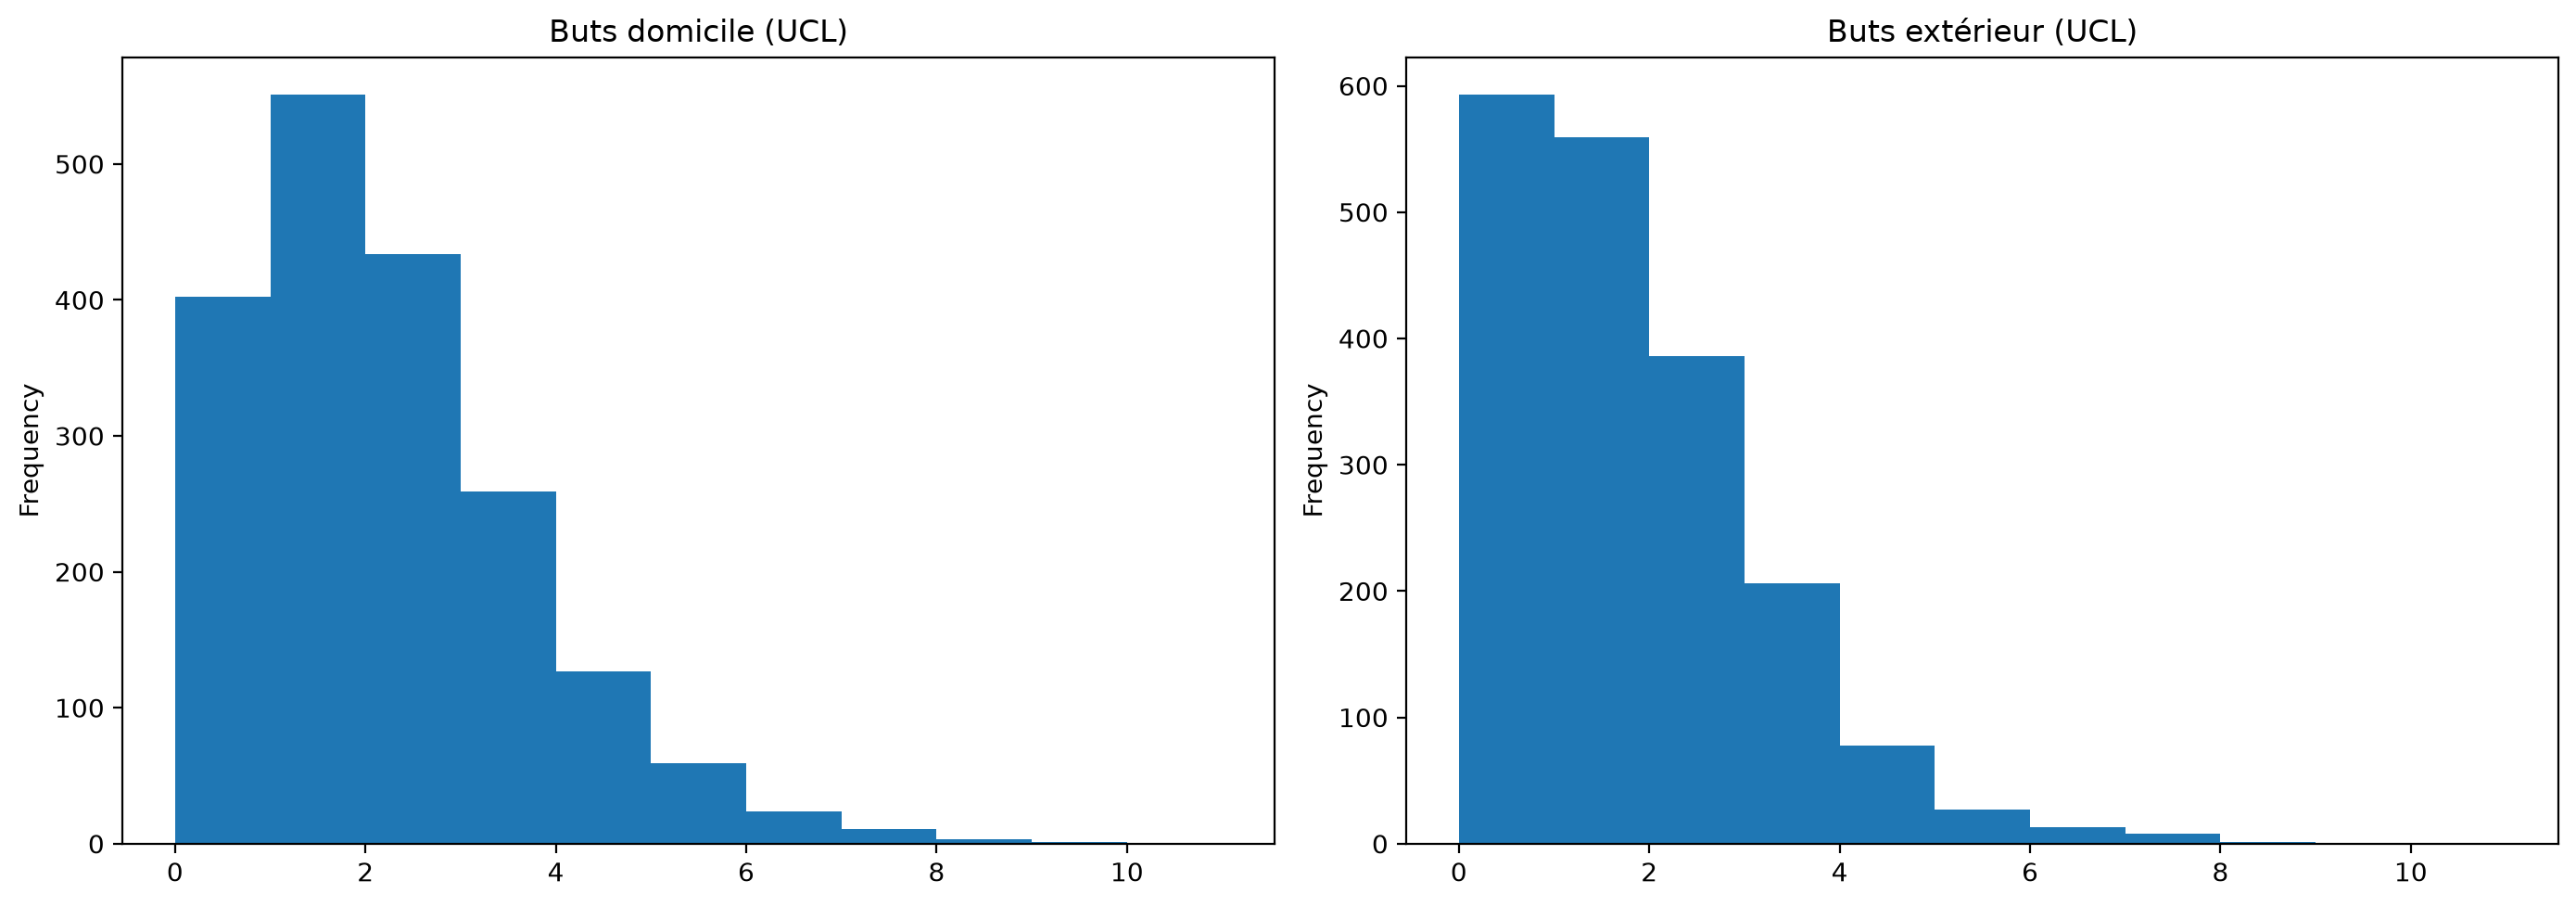

In [13]:
# CELLULE 12 : Distribution des buts UCL
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
bins = np.arange(0, 12)

ucl_games['home_club_goals'].plot(kind='hist', bins=bins, ax=ax1, title='Buts domicile (UCL)')
ucl_games['away_club_goals'].plot(kind='hist', bins=bins, ax=ax2, title='Buts extérieur (UCL)')

plt.tight_layout()
plt.show()

# 17. Performance récente (3 dernières saisons)

Même calcul que la cellule 13, restreint aux saisons **2023, 2024 et 2025**.

| Rang | Club | Victoires |
|---|---|---|
| 1 | Real Madrid | 28 |
| 2 | Paris Saint-Germain | 26 |
| 3 | Bayern Munich | 26 |
| 4 | Arsenal FC | 25 |
| 5 | FC Barcelona | 22 |
| 6 | Atlético de Madrid | 19 |
| 7 | Inter Milan | 19 |
| 8 | Borussia Dortmund | 19 |
| 9 | Manchester City | 16 |
| 10 | Liverpool FC | 15 |

**⚠️ Limites :** les saisons 2024 et 2025 utilisent le nouveau format (plus de matchs par saison : 189 et 188 contre 125 en 2023) ; la saison 2025 semble incomplète ; l'échantillon est petit (3 saisons) et les victoires brutes dépendent du parcours de chaque club.

In [14]:
# CELLULE 13 : Performance récente (3 dernières saisons)
max_season = ucl_games['season'].max()
min_season = max_season - 2
recent = ucl_games[ucl_games['season'] >= min_season]

print(f"\n🔥 PERFORMANCE RÉCENTE ({min_season} - {max_season}):")
home_wins = recent[recent['home_club_goals'] > recent['away_club_goals']]['home_club_name'].value_counts()
away_wins = recent[recent['away_club_goals'] > recent['home_club_goals']]['away_club_name'].value_counts()
recent_wins = home_wins.add(away_wins, fill_value=0).sort_values(ascending=False)

for i, (team, wins) in enumerate(recent_wins.head(10).items(), 1):
    print(f" {i:2d}. {team:30s} - {int(wins)} victoires")


🔥 PERFORMANCE RÉCENTE (2023 - 2025):
  1. Real Madrid                    - 28 victoires
  2. Paris Saint-Germain            - 26 victoires
  3. Bayern Munich                  - 26 victoires
  4. Arsenal FC                     - 25 victoires
  5. FC Barcelona                   - 22 victoires
  6. Atlético de Madrid             - 19 victoires
  7. Inter Milan                    - 19 victoires
  8. Borussia Dortmund              - 19 victoires
  9. Manchester City                - 16 victoires
 10. Liverpool FC                   - 15 victoires


### 18. Avantage du terrain

Comparaison des buts moyens à domicile et à l'extérieur en Ligue des champions :
- domicile : **1,74** buts ;
- extérieur : **1,36** buts ;
- écart : **+0,38 but** en faveur de l'équipe qui reçoit.

**Lecture :** il existe un avantage du terrain net en C1.

**⚠️ Limites :** analyse purement descriptive (aucun test statistique). Les finales et le tournoi final de 2019/20 à Lisbonne se jouent sur terrain neutre : l'équipe dite « à domicile » y est désignée de façon nominale.

In [15]:
# CELLULE 14 : Avantage du terrain
print("\n🏟️ AVANTAGE DU TERRAIN (UCL):")
home_avg = ucl_games['home_club_goals'].mean()
away_avg = ucl_games['away_club_goals'].mean()
print(f"Moyenne buts domicile: {home_avg:.2f}")
print(f"Moyenne buts extérieur: {away_avg:.2f}")
print(f"Avantage: +{home_avg - away_avg:.2f} buts")


🏟️ AVANTAGE DU TERRAIN (UCL):
Moyenne buts domicile: 1.74
Moyenne buts extérieur: 1.36
Avantage: +0.38 buts


# 19. Matrice de corrélation

Corrélation de Pearson entre toutes les colonnes numériques de `ucl_games`.

**Lecture :**
- les corrélations entre les buts et les autres variables sont **très faibles** (de l'ordre de ±0,04 à ±0,06) ;
- la corrélation quasi parfaite entre `game_id` et `season` (0,99) est triviale : les identifiants augmentent avec le temps ;
- les lignes de `NaN` (par exemple `home_club_position`) correspondent à des colonnes vides (ou constantes) pour la C1 : aucune corrélation n'est calculable.

**⚠️ Limite :** la matrice inclut des identifiants (`game_id`, `home_club_id`, `away_club_id`) qui n'ont aucune signification statistique.

In [16]:
# CELLULE 15 : Corrélation matrix (si données numériques)
print("\n🔗 CORRÉLATIONS:")
numeric_cols = ucl_games.select_dtypes(include=[np.number]).columns
correlation = ucl_games[numeric_cols].corr()
print(correlation)


🔗 CORRÉLATIONS:
                     game_id    season  home_club_id  away_club_id  \
game_id             1.000000  0.989024      0.059079      0.060041   
season              0.989024  1.000000      0.064112      0.065144   
home_club_id        0.059079  0.064112      1.000000     -0.017154   
away_club_id        0.060041  0.065144     -0.017154      1.000000   
home_club_goals     0.045602  0.040073     -0.040868      0.044033   
away_club_goals     0.056198  0.056073      0.063617     -0.047359   
home_club_position       NaN       NaN           NaN           NaN   
away_club_position       NaN       NaN           NaN           NaN   
attendance          0.037966  0.022958     -0.182577     -0.034218   

                    home_club_goals  away_club_goals  home_club_position  \
game_id                    0.045602         0.056198                 NaN   
season                     0.040073         0.056073                 NaN   
home_club_id              -0.040868         0.063617  

# 20. Heatmap de corrélation

Représentation graphique de la matrice précédente avec `seaborn.heatmap` : valeurs annotées, palette divergente `BrBG` centrée sur 0 (brun = corrélation négative, vert-bleu = positive).

**Lecture :** aucune relation forte n'apparaît avec les buts. Les cases vides correspondent aux colonnes sans données exploitables.

**⚠️ Limites :** les identifiants brouillent la lecture ; l'échelle de couleur n'est pas fixée entre −1 et 1 (`vmin` / `vmax`), ce qui peut déformer la perception des intensités.

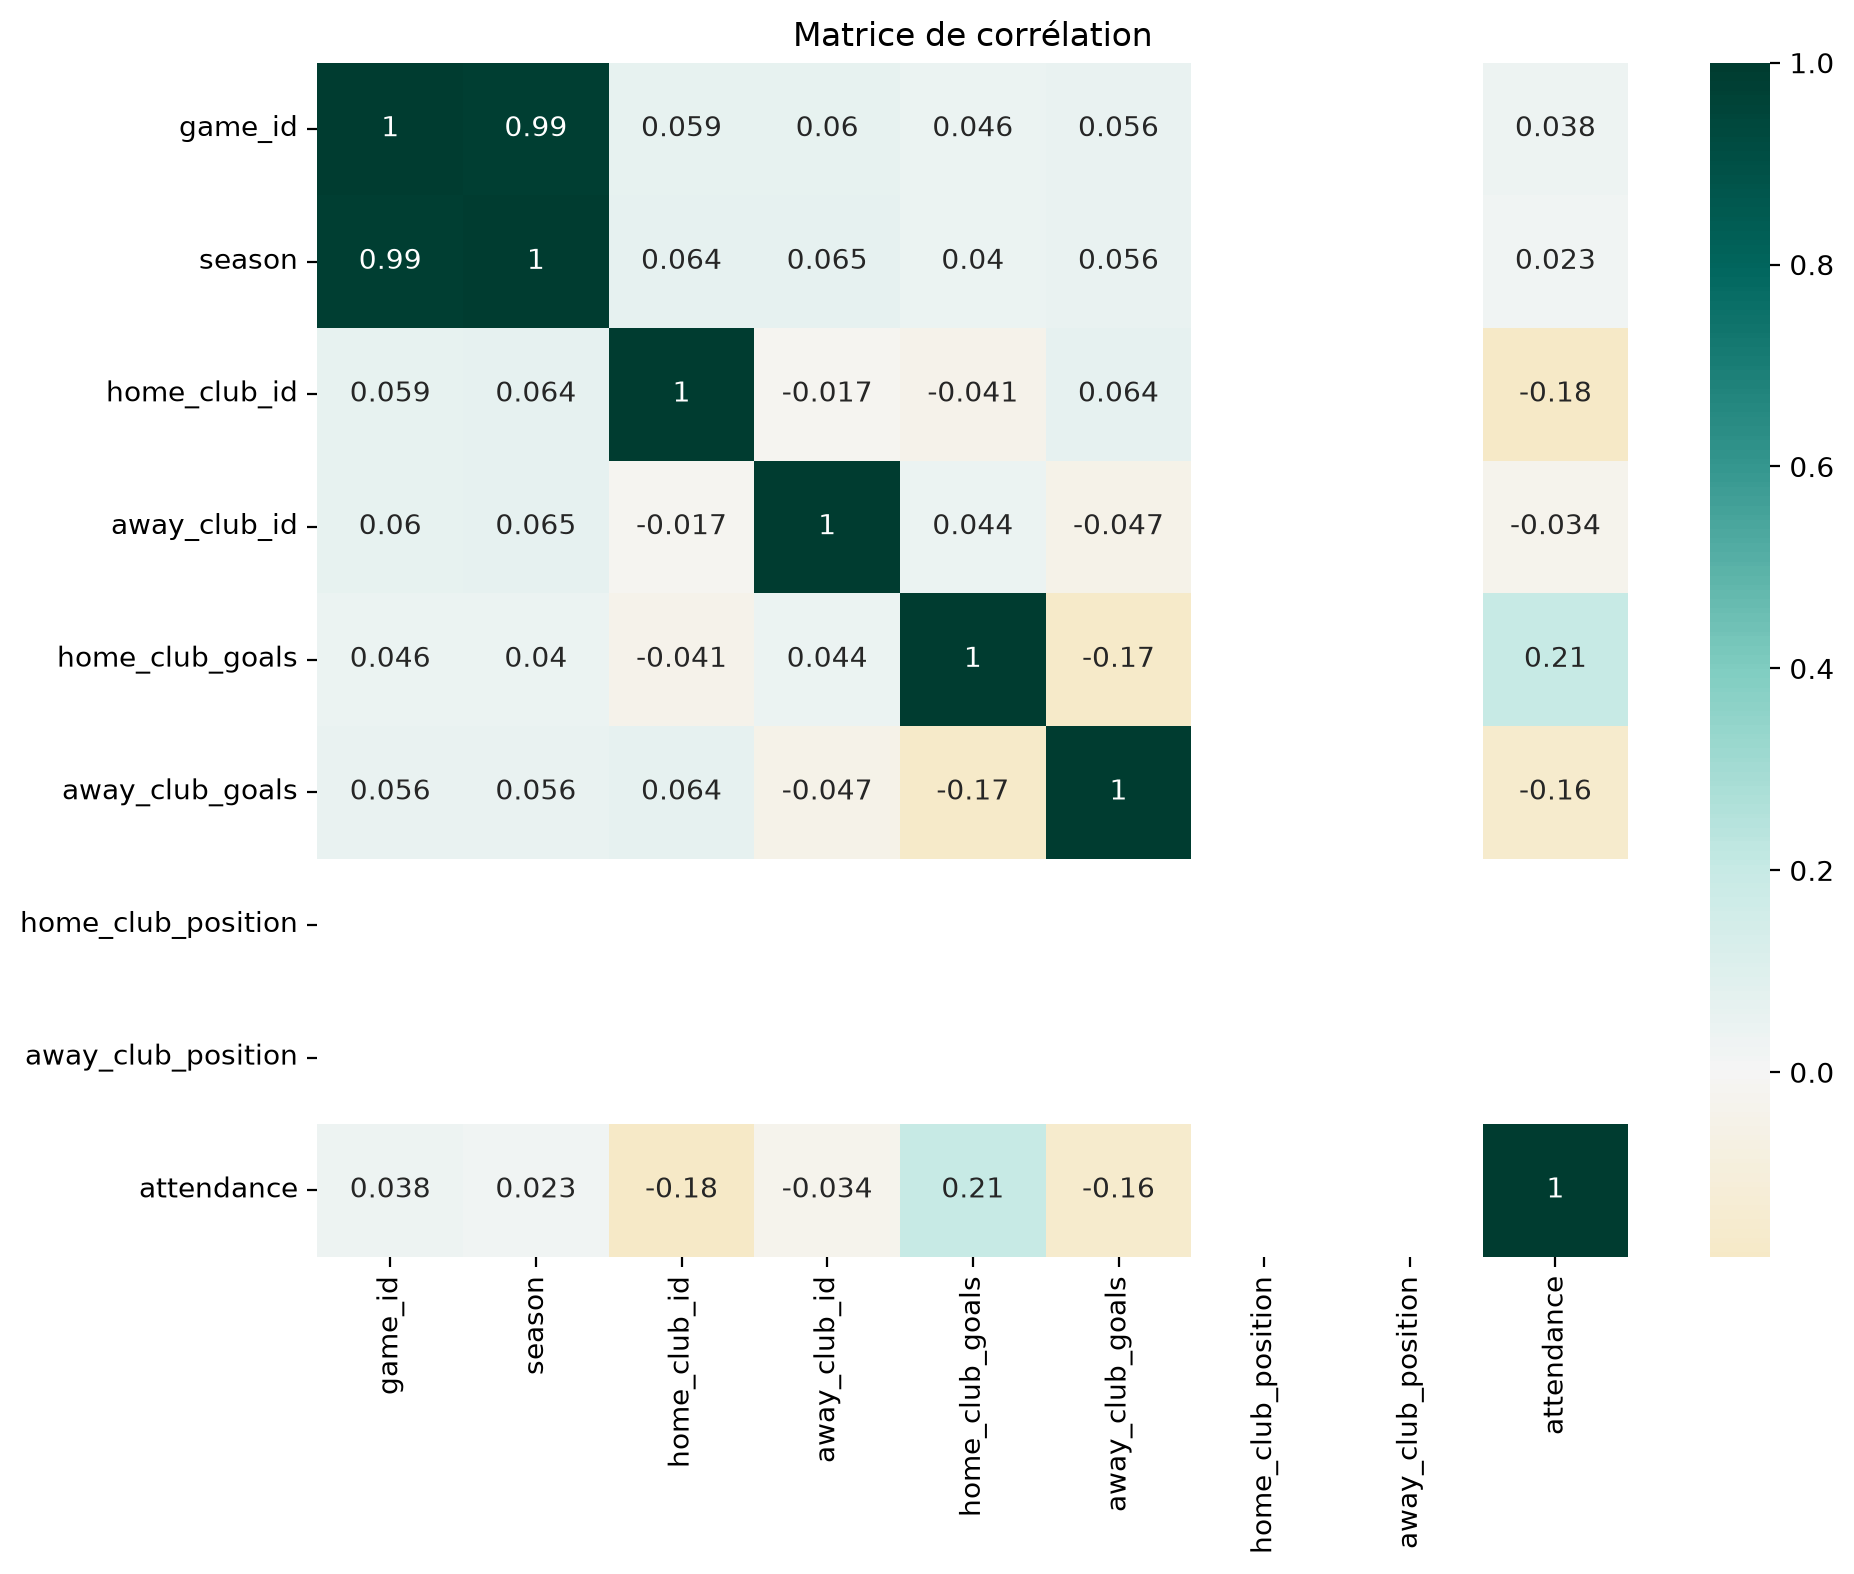

In [17]:
# CELLULE 16: Heatmap - CORRECT
plt.figure(figsize=(10, 8))  # ← figsize ICI, pas dans heatmap()

sns.heatmap(correlation, annot=True, center=0, cmap='BrBG')

plt.title('Matrice de corrélation')
plt.tight_layout()
plt.show()

# 22. Résumé de l'analyse exploratoire

Synthèse des principaux constats (création préalable d'une colonne `result` : victoire domicile, nul ou victoire extérieure).

- **Structure :** 1 871 matchs de Ligue des champions, saisons 2012–2025, 106 clubs différents, du 18/09/2012 au 06/05/2026.
- **Buts :** 1,74 à domicile contre 1,36 à l'extérieur.
- **Victoires à domicile :** 47,7 % des matchs.
- **Top 5 historique :** Real Madrid (112), Bayern Munich (111), FC Barcelone (85), Paris Saint-Germain (84), Manchester City (77).
- **Prochaines étapes :** fusion avec les Elo, création de variables (forme, confrontations directes), identification des phases (groupes / éliminatoires), modèle prédictif.

**⚠️ Limites :**
- les lignes « No missing goals data » et « No duplicate matches » sont des textes écrits en dur, **pas des vérifications calculées** (l'absence de buts manquants est toutefois cohérente avec le type `int64`) ;
- le nombre de clubs est compté sur `home_club_name` uniquement ;
- « All Time » désigne en réalité 2012–2025 ;
- pour la modélisation, le découpage train/test devra être **chronologique** afin d'éviter toute fuite d'information.

In [19]:
# CELLULE 17: Résumé de l'EDA

# D'ABORD: créer la colonne 'result' si elle n'existe pas
if 'result' not in ucl_games.columns:
    ucl_games['result'] = ucl_games.apply(
        lambda row: 'Home Win' if row['home_club_goals'] > row['away_club_goals']
        else ('Draw' if row['home_club_goals'] == row['away_club_goals'] else 'Away Win'),
        axis=1
    )

print("\n" + "="*70)
print("📊 RÉSUMÉ DE L'EDA - CHAMPIONS LEAGUE")
print("="*70)

print(f"\n✅ DATASET STRUCTURE:")
print(f"   - {len(ucl_games):,} Champions League matches")
print(f"   - {ucl_games['season'].min():.0f} - {ucl_games['season'].max():.0f} seasons")
print(f"   - {ucl_games['home_club_name'].nunique()} unique teams")

print(f"\n✅ DATA QUALITY:")
print(f"   - No missing goals data")
print(f"   - No duplicate matches")
print(f"   - Dates: {ucl_games['date'].min()} to {ucl_games['date'].max()}")

print(f"\n✅ KEY FINDINGS:")
print(f"   - Home teams avg: {ucl_games['home_club_goals'].mean():.2f} goals")
print(f"   - Away teams avg: {ucl_games['away_club_goals'].mean():.2f} goals")
print(f"   - Home win rate: {(ucl_games['result'] == 'Home Win').sum() / len(ucl_games) * 100:.1f}%")

print(f"\n🏆 Top Teams (All Time):")
print(total_wins.head(5).to_string())

print(f"\n📋 NEXT STEPS:")
print(f"   1. Merge with ELO ratings")
print(f"   2. Feature engineering (form, H2H, etc.)")
print(f"   3. Identify tournament phases (Groups/Knockouts)")
print(f"   4. Build predictive model")

print("\n" + "="*70)


📊 RÉSUMÉ DE L'EDA - CHAMPIONS LEAGUE

✅ DATASET STRUCTURE:
   - 1,871 Champions League matches
   - 2012 - 2025 seasons
   - 106 unique teams

✅ DATA QUALITY:
   - No missing goals data
   - No duplicate matches
   - Dates: 2012-09-18 to 2026-05-06

✅ KEY FINDINGS:
   - Home teams avg: 1.74 goals
   - Away teams avg: 1.36 goals
   - Home win rate: 47.7%

🏆 Top Teams (All Time):
home_club_name
Real Madrid            112.0
Bayern Munich          111.0
FC Barcelona            85.0
Paris Saint-Germain     84.0
Manchester City         77.0

📋 NEXT STEPS:
   1. Merge with ELO ratings
   2. Feature engineering (form, H2H, etc.)
   3. Identify tournament phases (Groups/Knockouts)
   4. Build predictive model



1. Qu'avez-vous étudié ?
Nous avons analysé 1,871 matchs de la Ligue des Champions de 2012 à 2025, avec 106 équipes différentes. On a regardé qui a gagné, combien de buts ils ont marqués, et si jouer à domicile change quelque chose.


3. Qu'avez-vous appris que vous ne saviez pas ce matin ?
L'avantage domicile est très fort : les équipes gagnent 47.7% de leurs matchs à la maison, mais seulement 20% en extérieur. C'est une différence énorme. On a aussi découvert que Real Madrid domine depuis 13 ans avec 112 victoires, c'est plus que toute autre équipe.



5. Quelle est votre découverte la plus solide ?
La qualité du club est le facteur le plus important. Real Madrid gagne 112 matchs, un petit club en gagne 5. C'est 20 fois plus ! Ça montre que pour prédire les résultats, il faut savoir qui joue, pas juste si c'est à domicile ou pas.



7. Pourquoi devrais-je vous croire ?
Nos données sont complètes et propres : pas de buts manquants, pas de doublons, 1,871 matchs sur 14 saisons. On a vérifié les chiffres. Et les patterns sont évidents dans les graphiques - l'avantage domicile se voit vraiment dans les histogrammes.



9. Quelle est la principale limite de votre analyse ?
On manque les données sur les joueurs : on ne sait pas qui est blessé, qui joue vraiment, quelle est la valeur marchande réelle. Les données sont aussi historiques - Real Madrid dominait en 2015, mais l'équipe change tous les ans. Le passé ne prédit pas toujours l'avenir.


Conclusion :
"Nous avons étudié 1,871 matchs de Ligue des Champions. On a découvert que l'avantage domicile est très fort et que la qualité du club change tout. Les données sont complètes et les patterns sont clairs. La limite : on n'a pas les infos sur les blessures et les données historiques changent chaque saison."